# A single star in Fourier space

Notebook 1 of 3, for *Faint Companions to Hot Stars*: §2.1, eqs. 1–8, Figs. 1–2,
Apps. A and B.1.

Two facts about the Fourier transform of a spectral line carry the whole method.
Shape and position separate — broadening lives in $|\tilde S|$, velocity lives
in $\arg\tilde S$. And the broadening kernels multiply, so their logarithms add,
which turns a product of physical effects into a sum of fittable terms.

The second half of the notebook puts that to work measuring $v\sin i$ from a
single line, and arrives at the lesson that governs companion detection as well:
what you can measure is whatever a smooth baseline cannot absorb.

### Conventions

Velocities are in km/s and the Fourier conjugate variable $\zeta$ is in s/km.
Kernel widths $v_G$ and $v_\gamma$ are FWHM in km/s. The Fourier grid is always
`np.fft.rfftfreq(N, d=dv)[1:]`: positive frequencies, DC dropped. Spectra are
continuum-normalised line residuals, so $S = f/f_c - 1 \le 0$ for absorption.

Every quantity below is built once in plain numpy and then recomputed with the
library call, with the agreement printed.

### The fiducial star

Unless a cell says otherwise, this notebook and the next two use one line:

| quantity | value |
|---|---|
| line depth | 0.5 |
| $v_G$ (Gaussian FWHM) | 15 km/s |
| $v_\gamma$ (Lorentzian FWHM) | 5 km/s |
| $v\sin i$ | 20 km/s ($\epsilon = 0.5$) |
| grid | $dv = 1$ km/s, $N = 2048$, $\lambda_0 = 5875.6$ Å |
| $\sigma_{\rm pix}$ | 0.01 |

This notebook departs from it twice, and says so where it happens: the first
section uses a bare Gaussian kernel, which is the least you need in order to see
the shape/position split, and the second uses the paper's own Fig. 2 parameters.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import specbeat
except ModuleNotFoundError:
    # Source checkout without `pip install -e .`: add the package's src/ to the path.
    import sys
    from pathlib import Path
    for _p in [Path.cwd(), *Path.cwd().parents]:
        if (_p / "src" / "specbeat").is_dir():
            sys.path.insert(0, str(_p / "src"))
            break

from specbeat import kernels, simulate
from specbeat.plotting import set_paper_style, regime_label

set_paper_style()

{'font.family': 'sans-serif',
 'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
 'font.size': 11.0,
 'axes.titlesize': 11.0,
 'axes.labelsize': 11.0,
 'xtick.labelsize': 10.0,
 'ytick.labelsize': 10.0,
 'legend.fontsize': 8.0,
 'axes.linewidth': 0.8,
 'xtick.major.width': 0.7,
 'ytick.major.width': 0.7,
 'xtick.direction': 'in',
 'ytick.direction': 'in',
 'lines.linewidth': 1.2,
 'figure.dpi': 110,
 'savefig.dpi': 300,
 'savefig.bbox': 'tight',
 'axes.grid': False}

## Shape and position separate

Take a single absorption line at velocity $v_a$, narrow enough that its
intrinsic profile is a delta function beside the broadening (eqs. 1–3):

$$S(\lambda) = U^{(a)}(\lambda) \circledast f^{(a)}(\lambda) + \text{noise},
\qquad
f^{(a)}(\lambda) \simeq -\alpha_a\,\delta\!\left[\lambda-(\lambda_0+v_a)\right].$$

Its transform is the kernel times a pure phase,

$$\tilde S(\zeta) \simeq -\alpha_a\, \tilde U^{(a)}(\zeta)\,
e^{-i2\pi\zeta(\lambda_0+v_a)},$$

so the velocity sits entirely in the phase, and the amplitude sees only the
kernel: $\ln|\tilde S| \simeq \ln|\tilde U^{(a)}| + \text{const}$ (eq. 4). The
kernel is itself a product of three factors (eq. 5), which makes its
log-amplitude a sum (eq. 6):

$$\tilde U^{(a)} = \tilde K_\gamma \tilde K_G \tilde K_r,\qquad
\ln|\tilde S| \simeq -\pi v_\gamma|\zeta| - \frac{\pi^2 v_G^2}{4\ln 2}\zeta^2
+ k(\zeta; v_r, \epsilon) + \text{const},$$

with $\tilde K_\gamma = e^{-\pi v_\gamma |\zeta|}$,
$\tilde K_G = e^{-(\pi\zeta)^2 v_G^2/4\ln2}$ (eq. A.1), and $k$ the Bessel-form
rotational log-kernel (eq. A.2). Two assumptions are doing work: the grid has a
uniform velocity step, so that a Doppler shift is a translation, and the
intrinsic line is narrow enough for the delta-function limit.

The cells below build a Gaussian-broadened line by real-space convolution
without touching the library, check that its transform is shift-invariant in
amplitude and shifts by exactly $-2\pi\zeta\,\Delta v$ in phase, compare it
against `kernels.gaussian_broadening_FT`, verify the additivity of eq. 6 against
the independent code path in `simulate.kernel_amp`, and close by reproducing
Fig. 1.

In [2]:
# Grid for this section. Deviation from the fiducial: coarser dv and a bare Gaussian
# kernel -- the minimal configuration for demonstrations 1-2.
rng = np.random.default_rng(1)
dv, N = 5.0, 1024
wavelength_0 = 5875.6
wave = simulate.generate_wavelength_grid(wavelength_0, dv, N)
print(f"grid: N={N}, dv={dv} km/s, span={N*dv:.0f} km/s, "
     f"lambda in [{wave.min():.1f}, {wave.max():.1f}] AA")

grid: N=1024, dv=5.0 km/s, span=5120 km/s, lambda in [5825.6, 5925.9] AA


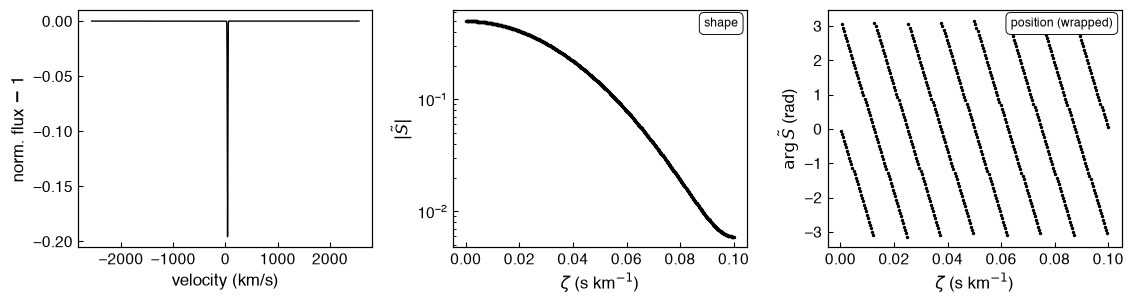

In [3]:
# (1) By hand: delta line at v_shift, convolved with a unit-sum Gaussian
#     kernel of FWHM vG. No specbeat calls.
vG, line_depth, v_shift = 12.0, 0.5, 40.0

sigma_px = (vG / dv) / (2 * np.sqrt(2 * np.log(2)))       # FWHM -> sigma, pixels
kx = np.arange(-8 * int(np.ceil(sigma_px)), 8 * int(np.ceil(sigma_px)) + 1)
gauss_kernel = np.exp(-0.5 * (kx / sigma_px) ** 2)
gauss_kernel /= gauss_kernel.sum()                        # unit sum -> K(0)=1

def delta_line_at(v):
    d = np.zeros(N)
    d[N // 2 + int(round(v / dv))] = -line_depth
    return d

by_hand_line = np.convolve(delta_line_at(v_shift), gauss_kernel, mode="same")

S = np.fft.rfft(by_hand_line)
zeta = np.fft.rfftfreq(N, d=dv)[1:]                       # DC dropped
amp, phase = np.abs(S)[1:], np.angle(S)[1:]

velocity = (np.arange(N) - N // 2) * dv
fig, axes = plt.subplots(1, 3, figsize=(10.5, 2.9))
axes[0].plot(velocity, by_hand_line, "k-", lw=0.9)
axes[0].set_xlabel("velocity (km/s)"); axes[0].set_ylabel("norm. flux $-$ 1")
axes[1].semilogy(zeta, amp, "k.", ms=2.5)
axes[1].set_xlabel(r"$\zeta$ (s km$^{-1}$)"); axes[1].set_ylabel(r"$|\tilde S|$")
axes[2].plot(zeta, phase, "k.", ms=2.5)
axes[2].set_xlabel(r"$\zeta$ (s km$^{-1}$)"); axes[2].set_ylabel(r"$\arg\tilde S$ (rad)")
regime_label(axes[1], "shape", loc="upper right")
regime_label(axes[2], "position (wrapped)", loc="upper right")
fig.tight_layout()
plt.show()

Why does the raw phase hop by $\approx\pi$ between consecutive $\zeta$? It is a
perfectly linear ramp, displayed wrapped and undersampled. The FFT measures
position from the first pixel of the array, not from the line: here the line
sits at $x_0 = (N/2)\,dv + v_{\rm shift} = 2600$ km/s from the array origin, so
$\arg\tilde S = -2\pi\zeta x_0$, plus $\pi$ from the negative line depth. Per
$\zeta$ sample ($\Delta\zeta = 1/N dv$) the phase therefore steps by

$$-2\pi\,x_0\,\Delta\zeta \;=\; -2\pi\cdot\frac{2600}{5120}
\;=\; -1.016\,\pi \quad\text{per bin},$$

just past half a turn each sample. Wrapped into $(-\pi,\pi]$, consecutive points
appear to alternate by $\sim\pi$, and the leftover $0.016\pi$ accumulates into
the slow diagonal stripes. Remove the known grid ramp — reference the phase to
the segment centre and flip the absorption sign — and what remains is the
informative part: a gentle ramp whose slope is the line's velocity. Keeping
track of $x_0$ this way is the first thing the phase channel of notebook 2 does,
as `phase.phase_observable`.

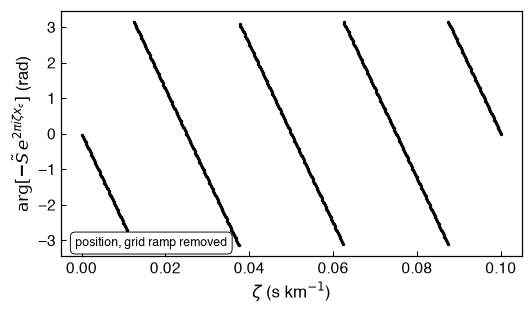

velocity from the deramped phase slope: 40.000 km/s (injected v_shift = 40.0)


In [4]:
# Deramp: reference the phase to the segment centre x_c = (N//2)*dv and flip
# the absorption sign; the leftover slope IS the line's velocity.
x_c = (N // 2) * dv
S0 = -S[1:] * np.exp(2j * np.pi * zeta * x_c)      # sign flip + deramp
phase_deramped = np.unwrap(np.angle(S0))
v_from_phase = np.polyfit(zeta, phase_deramped, 1)[0] / (-2 * np.pi)

fig, ax = plt.subplots(figsize=(5.4, 2.9))
ax.plot(zeta, np.angle(S0), "k.", ms=2.5)
ax.set_xlabel(r"$\zeta$ (s km$^{-1}$)")
ax.set_ylabel(r"$\arg[-\tilde S\, e^{2\pi i \zeta x_c}]$ (rad)")
regime_label(ax, "position, grid ramp removed", loc="lower left")
plt.show()
print(f"velocity from the deramped phase slope: {v_from_phase:.3f} km/s "
     f"(injected v_shift = {v_shift})")

In [5]:
# Shift the SAME line to a different velocity: |S~| must not change; the
# phase must change by exactly -2*pi*zeta*Delta_v (eq. 3).
v_shift2 = 90.0
S2 = np.fft.rfft(np.convolve(delta_line_at(v_shift2), gauss_kernel, mode="same"))[1:]

d_v = v_shift2 - v_shift
dphase_obs = np.angle(np.exp(1j * (np.angle(S2) - phase)))          # wrapped
dphase_pred = np.angle(np.exp(-2j * np.pi * zeta * d_v))

print("check 1a  |S~| shift-invariant:      ",
     np.allclose(np.abs(S2), amp, rtol=1e-10))
print("check 1b  phase shift = -2 pi zeta dv:",
     np.allclose(dphase_obs, dphase_pred, atol=1e-8))
print("check 1c  library velocity_shift():   ",
     np.allclose(np.angle(kernels.velocity_shift(zeta, d_v)), dphase_pred, atol=1e-12))

check 1a  |S~| shift-invariant:       True
check 1b  phase shift = -2 pi zeta dv: True
check 1c  library velocity_shift():    True


In [6]:
# (2) The by-hand |S~| against the library's ANALYTIC Gaussian kernel:
#     |S~(zeta)| = line_depth * K_G(zeta; vG), with K_G(0)=1 by the unit-sum
#     normalization above. Discretization of the truncated kernel limits the
#     agreement, not conventions.
band = zeta <= 0.02
model = line_depth * kernels.gaussian_broadening_FT(zeta[band], vG=vG)
print("check 2   by-hand |S~| = depth * gaussian_broadening_FT:",
     np.allclose(amp[band], model, rtol=1e-3))

check 2   by-hand |S~| = depth * gaussian_broadening_FT: True


In [7]:
# (3) Additivity (eq. 6): sum of the three log-kernels vs simulate.kernel_amp,
#     which multiplies the LINEAR amplitudes internally -- independent path.
vgamma_f, vG_f, vr_f, eps_f = 5.0, 10.0, 50.0, 0.5        # paper Fig. 1/2 values

lnK_sum = (np.log(kernels.lorentzian_broadening_FT(zeta, gamma=vgamma_f))
           + np.log(kernels.gaussian_broadening_FT(zeta, vG=vG_f))
           + kernels.rotational_kernel(zeta, vr_f, eps_f, return_log=True))
lnK_lib = np.log(simulate.kernel_amp(zeta, vG_f, vgamma_f, vr_f, eps_f))
print("check 3   sum of log-kernels = kernel_amp:",
     np.allclose(lnK_sum, lnK_lib, atol=1e-10))

check 3   sum of log-kernels = kernel_amp: True


$|\tilde S(0)| = |\sum_i S_i|$ measures the continuum mean, not the line shape.
`amplitude.fourier_log_amplitude` drops it at the source, via
`rfftfreq(N, d=dv)[1:]`, so it cannot re-enter anywhere downstream.

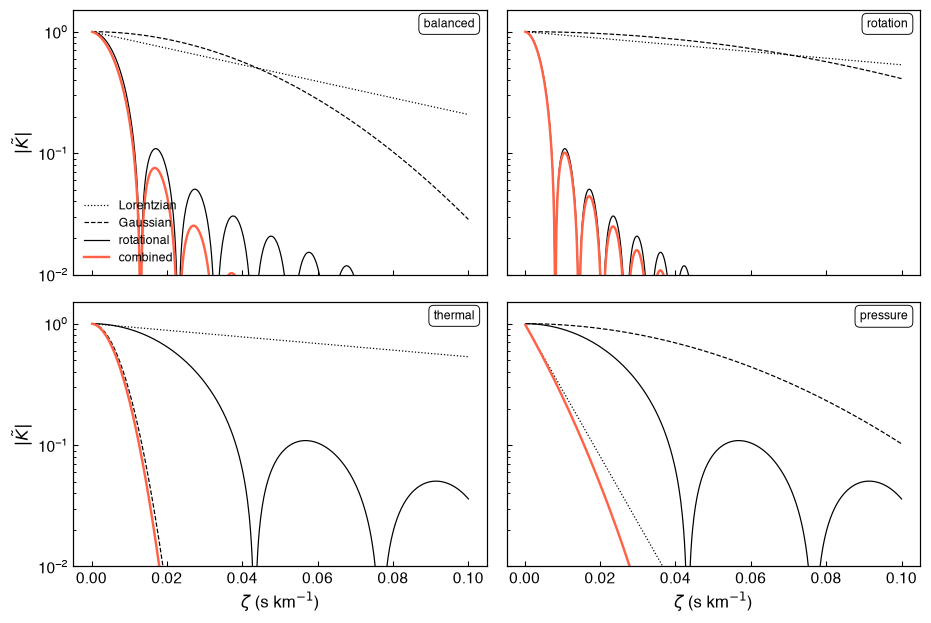

In [8]:
# (4) cf. paper Fig. 1 -- the three kernels and their product, four regimes.
regimes = {
    "balanced":           dict(vgamma=5, vG=10, vr=50, eps=0.5),
    "rotation":           dict(vgamma=2, vG=5,  vr=80, eps=0.5),
    "thermal":            dict(vgamma=2, vG=60, vr=15, eps=0.5),
    "pressure":           dict(vgamma=40, vG=8, vr=15, eps=0.5),
}
fig, axes = plt.subplots(2, 2, figsize=(8.6, 5.8), sharex=True, sharey=True)
for ax, (name, p) in zip(axes.flat, regimes.items()):
    ax.semilogy(zeta, kernels.lorentzian_broadening_FT(zeta, gamma=p["vgamma"]),
                "k:", lw=0.8, label="Lorentzian")
    ax.semilogy(zeta, kernels.gaussian_broadening_FT(zeta, vG=p["vG"]),
                "k--", lw=0.8, label="Gaussian")
    ax.semilogy(zeta, np.abs(kernels.rotational_kernel(zeta, p["vr"], p["eps"],
                                                       return_log=False)),
                "k-", lw=0.8, label="rotational")
    ax.semilogy(zeta, simulate.kernel_amp(zeta, p["vG"], p["vgamma"], p["vr"], p["eps"]),
                "-", color="tomato", lw=1.6, label="combined")
    ax.set_ylim(1e-2, 1.5)
    regime_label(ax, name, loc="upper right")
axes[0, 0].legend(loc="lower left", frameon=False)
for ax in axes[-1]: ax.set_xlabel(r"$\zeta$ (s km$^{-1}$)")
for ax in axes[:, 0]: ax.set_ylabel(r"$|\tilde K|$")
fig.tight_layout()
plt.show()

So: shape goes to $|\tilde S|$, position to $\arg\tilde S$, and the kernels
multiply while their logs add. Everything from here on is bookkeeping on the
additive terms of $\ln|\tilde S|$.

Real data needs more preparation than this. Resample onto a uniform-$dv$
log-$\lambda$ grid, rectify locally, and taper the segment edges — a Tukey
window, say — before the FFT; §4 of the paper covers it. The `rfftfreq[1:]`
convention stays as it is.

## Measuring rotation

Fit the log-amplitude of a single line with a smooth baseline plus the
rotational log-kernel (eq. 7),

$$y_i = a_0 + a_1\zeta_i + a_2\zeta_i^2 + k(\zeta_i; a_3, \epsilon) + n_i,$$

and expand the model for slow rotation (eq. 8):

$$\ln|\tilde S| \simeq -\pi v_\gamma|\zeta|
- \pi^2\!\left[\frac{v_G^2}{4\ln2} - \left(\frac{\epsilon}{15}-\frac12\right)v_r^2\right]\zeta^2
- \frac{\pi^4}{4}\!\left[\frac{1}{24}-\frac{\epsilon}{63}\right]v_r^4\,\zeta^4 + \dots$$

The baseline $(a_0,a_1,a_2)$ absorbs everything through $\zeta^2$, and that
includes the rotational $\zeta^2$ term, which is degenerate with $v_G$ and so
carries no information. The leading measurable rotation signal is the $\zeta^4$
term. That is the entire content of the rotation measurement, and the same
argument comes back for the companion in notebook 3.

The fit is a profiled weighted least squares (App. C.1). For a fixed trial
$a_3$, with $M = [1,\zeta,\zeta^2]$ and $P = M(M^\top W M)^{-1}M^\top W$,

$$\mathbf e = (I-P)(\mathbf y-\mathbf k),\qquad
\chi^2(a_3) = \mathbf e^\top W\,\mathbf e,\qquad
I_{v_r} \approx \Big(\tfrac{dk}{dv_r}\Big)^{\!\top}(I-P)^\top W(I-P)\,\tfrac{dk}{dv_r}
\;\;\text{(eq. C.6)}.$$

This holds as long as the fitted band stays below the rotational kernel's first
zero, so that the expansion applies, and the Fourier-amplitude noise is Gaussian
and independent with a known $\sigma_A$. The fitted band is a fixed limit in
$\zeta$, placed where the *noise-free* amplitude reaches ${\rm SNR}\approx3$
(the paper's App. B convention); why the limit sits there comes at the end of
the section.

What follows is a $\chi^2(v\sin i)$ scan done by hand, the low-$v$ degeneracy
seen without noise, the classical first-zero method for comparison, and the
Cramér–Rao bound against Monte Carlo — both where the estimator works and where
it fails.

In [9]:
from specbeat import amplitude, power

# Deviation from the fiducial: the paper's Fig. 2 line parameters -- EXCEPT
# the noise. The paper's sigma_pix = 0.02 puts THIS estimator in its breakdown
# regime (a fraction of noise seeds collapses to the low-v degeneracy of
# demonstration 2; demonstration 4b measures how often). The headline fit runs
# at the fiducial sigma_pix = 0.01 so it is reliable across noise seeds;
# demonstration 4b returns to 0.02.
vsini_true, vG_2, vgamma_2, eps_2 = 50.0, 10.0, 5.0, 0.5
sigma_pix = 0.01

spec_clean, _, _ = simulate.generate_simulated_spectrum(
    wave, dv, wavelength_0=wavelength_0, line_depth=0.6, v=0.0,
    vG=vG_2, gamma=vgamma_2, vsini=vsini_true, epsilon=eps_2,
    second_component=False)
spec_clean = np.asarray(spec_clean, float)

fit band: 59 modes, zeta <= 0.0115 s/km


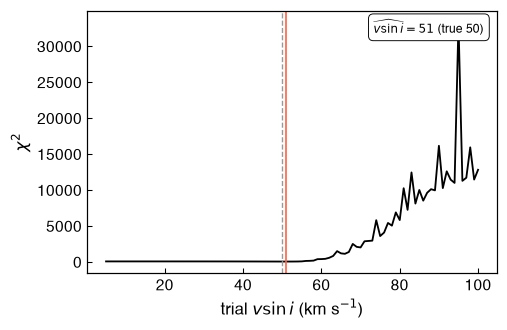

recovered v sin i = 51.0 km/s   (true 50)


In [10]:
# (1) chi2(vsini) by hand. specbeat ships no fit_vsini() wrapper -- this
#     short loop IS the fit, using only public building blocks (the same
#     WLS machinery detect uses for the companion scan in notebook 03).
rng_fit = np.random.default_rng(0)     # fresh generator: cell is re-runnable
spec_noisy = spec_clean + rng_fit.normal(0.0, sigma_pix, N)

amp_obs, _, zeta_obs, sigma_A = amplitude.fourier_log_amplitude(
    spec_noisy, dv, normalize_to_snr=False)
# The fitted band is a FIXED limit in zeta (the paper's App. B convention):
# place it where the NOISE-FREE amplitude reaches SNR = 3, so no noise
# realization chooses its own band.
amp_cln0, _, _, _ = amplitude.fourier_log_amplitude(
    spec_clean, dv, normalize_to_snr=False)
z_edge, _, _ = amplitude.truncate_to_snr_cutoff(
    zeta_obs, np.log(amp_cln0), amp_cln0, amp_cln0 / sigma_A, threshold=3.0)
zeta_band = z_edge.max()
zeta_fit, _, amp_fit = amplitude.truncate_to_snr_cutoff(
    zeta_obs, np.log(amp_obs), amp_obs, amp_obs / sigma_A, zeta_max=zeta_band)
log_amp_fit = np.log(amp_fit)
weights = (amp_fit / sigma_A) ** 2
M = amplitude.construct_log_amp_model_matrix(zeta_fit, 0.0,
                                             n_cos_terms=None, n_baseline=2)
print(f"fit band: {len(zeta_fit)} modes, zeta <= {zeta_fit.max():.4f} s/km")

def chi2_at_vsini(v):
    k_trial = kernels.rotational_kernel(zeta_fit, v, eps_2, return_log=True)
    _, _, chi2 = amplitude.bounded_weighted_least_squares(
        M, log_amp_fit - k_trial, weights, bounds=None)
    return chi2

vsini_grid = np.linspace(5.0, 100.0, 96)
chi2_grid = np.array([chi2_at_vsini(v) for v in vsini_grid])
vsini_hat = vsini_grid[np.argmin(chi2_grid)]

fig, ax = plt.subplots(figsize=(4.8, 3.1))
ax.plot(vsini_grid, chi2_grid, "k-")
ax.axvline(vsini_true, color="0.6", ls="--", lw=0.9)
ax.axvline(vsini_hat, color="tomato", lw=1.1)
ax.set_xlabel(r"trial $v\sin i$ (km s$^{-1}$)"); ax.set_ylabel(r"$\chi^2$")
regime_label(ax, rf"$\widehat{{v\sin i}} = {vsini_hat:.0f}$ (true {vsini_true:.0f})")
plt.show()
print(f"recovered v sin i = {vsini_hat:.1f} km/s   (true {vsini_true:.0f})")

At the paper's $\sigma_{\rm pix}=0.02$ this same fit collapses to the low-$v$
grid edge on a fraction of noise seeds (2 of 16 in demonstration 4b below), and
when it does, it does so decisively — $\chi^2$ prefers the degenerate valley
outright, not marginally. The next cell shows the degeneracy that makes the
collapse possible, and the last one measures how often it happens.

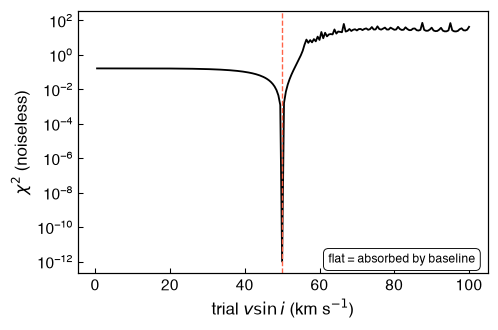

In [11]:
# (2) The low-v degeneracy, noiseless: chi2 is FLAT for small trial values
#     (the kernel's shape over this band is itself ~quadratic there, so the
#     free a2 absorbs it); only the zeta^4-order mismatch localizes the fit.
amp_c, log_amp_c, zeta_c, _ = amplitude.fourier_log_amplitude(
    spec_clean, dv, normalize_to_snr=False)
zmask = zeta_c <= zeta_fit.max()
M_c = amplitude.construct_log_amp_model_matrix(zeta_c[zmask], 0.0,
                                               n_cos_terms=None, n_baseline=2)
w_c = np.ones(zmask.sum())

def chi2_clean(v):
    k_trial = kernels.rotational_kernel(zeta_c[zmask], v, eps_2, return_log=True)
    _, _, chi2 = amplitude.bounded_weighted_least_squares(
        M_c, log_amp_c[zmask] - k_trial, w_c, bounds=None)
    return chi2

vv = np.linspace(0.5, 100.0, 200)
cc = np.array([chi2_clean(v) for v in vv])

fig, ax = plt.subplots(figsize=(4.8, 3.1))
ax.semilogy(vv, cc + 1e-12, "k-")
ax.axvline(vsini_true, color="tomato", ls="--", lw=0.9)
ax.set_xlabel(r"trial $v\sin i$ (km s$^{-1}$)")
ax.set_ylabel(r"$\chi^2$ (noiseless)")
regime_label(ax, "flat = absorbed by baseline", loc="lower right")
plt.show()

### The classical first-zero method

The textbook estimate takes $v\sin i$ from the first zero of the rotational
kernel, $x_1 = 2\pi\zeta_{\rm zero}v\sin i$, with $x_1$ the ($\epsilon$-dependent)
first root of eq. A.2. The comparison below grants the method more than a real
analyst would have: the noisy minimum is searched inside a window
$[0.5, 1.8]\times$ the *true* zero location. Even with that help, noise wiggles
capture the minimum on a fair fraction of seeds.

In [12]:
# (3) x1 from the model (once), then per-seed noisy minima.
x_grid = np.linspace(0.01, 10.0, 20000)
Kr = kernels.rotational_kernel(x_grid / (2 * np.pi * vsini_true), vsini_true,
                               eps_2, return_log=False)
x1 = x_grid[np.where(np.diff(np.sign(Kr)))[0][0]]
zeta_zero_true = x1 / (2 * np.pi * vsini_true)
print(f"x1 = {x1:.3f} (eps = {eps_2})   ->   true zeta_zero = {zeta_zero_true:.5f} s/km\n")

sigma_fz = 0.005                       # generous: 2x lower noise than the WLS demo
print(f"{'seed':>5} {'zeta_min':>9} {'vsini_first_zero':>17}   (true {vsini_true:.0f} km/s)")
for seed in range(6):
    r = np.random.default_rng(seed)
    sn = spec_clean + r.normal(0.0, sigma_fz, N)
    a_n = np.abs(np.fft.rfft(sn))[1:]
    win = (zeta_obs >= 0.5 * zeta_zero_true) & (zeta_obs <= 1.8 * zeta_zero_true)
    z_min = zeta_obs[win][np.argmin(a_n[win])]
    print(f"{seed:>5} {z_min:>9.5f} {x1 / (2 * np.pi * z_min):>17.1f}")

x1 = 4.081 (eps = 0.5)   ->   true zeta_zero = 0.01299 s/km

 seed  zeta_min  vsini_first_zero   (true 50 km/s)
    0   0.01270              51.2
    1   0.01309              49.6
    2   0.02109              30.8
    3   0.02266              28.7
    4   0.01289              50.4
    5   0.01348              48.2


Two of six seeds land 20 km/s low — a noise dip beat the physical notch, with a
truth-centred search window and four times lower noise than the weighted fit
above had to work with. The full-band weighted fit has no comparable failure at
this noise level, because it uses every mode, weighted, rather than a single
point. This is the argument behind Fig. 2 of the paper, quantified.

### The Cramér–Rao bound, and where the estimator breaks

The two regimes are worth separating. Below about $\sigma_{\rm pix} = 0.01$ here,
the Monte-Carlo error scatters around the Cramér–Rao bound $1/\sqrt{I_{v_r}}$
(eq. C.6) and the estimator tracks it. At larger $\sigma_{\rm pix}$ the
$\chi^2(v\sin i)$ landscape loses its minimum on some realizations and the
optimizer pins at the search boundary. That is a failure mode rather than a
larger error bar, and averaging the two together would misrepresent both. It is
the same effect behind the paper's remark that the precision curves terminate
where fewer than seven Fourier modes of the noise-free model exceed
${\rm SNR}=3$.

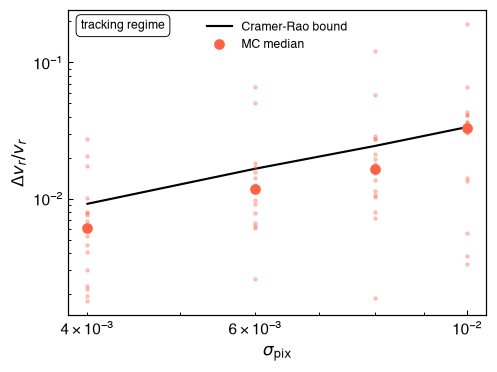

In [13]:
# (4a) tracking regime
from scipy.optimize import minimize_scalar

def band_edge(sp):
    # Fixed band for noise level sp: noise-free amplitude SNR >= 3.
    sA_ = amplitude.amp_noise_sigma(sp, n=N)
    z_, _, _ = amplitude.truncate_to_snr_cutoff(
        zeta_c, np.log(amp_c), amp_c, amp_c / sA_, threshold=3.0)
    return z_.max()

def fit_vsini_once(spec_n, zmax):
    a_, _, z_, sA_ = amplitude.fourier_log_amplitude(spec_n, dv, normalize_to_snr=False)
    zf_, _, af_ = amplitude.truncate_to_snr_cutoff(z_, np.log(a_), a_, a_ / sA_,
                                                   zeta_max=zmax)
    yf_, w_ = np.log(af_), (af_ / sA_) ** 2
    Mf_ = amplitude.construct_log_amp_model_matrix(zf_, 0.0, n_cos_terms=None,
                                                   n_baseline=2)
    def c2(v):
        kk = kernels.rotational_kernel(zf_, v, eps_2, return_log=True)
        return amplitude.bounded_weighted_least_squares(Mf_, yf_ - kk, w_, bounds=None)[2]
    return minimize_scalar(c2, bounds=(5.0, 120.0), method="bounded",
                           options={"xatol": 0.05}).x

def crb_frac_at(sp):
    sigma_A_lv = amplitude.amp_noise_sigma(sp, n=N)
    zf_, _, af_ = amplitude.truncate_to_snr_cutoff(
        zeta_c, np.log(amp_c), amp_c, amp_c / sigma_A_lv, threshold=3.0)
    w_ = (af_ / sigma_A_lv) ** 2
    Mf_ = amplitude.construct_log_amp_model_matrix(zf_, 0.0, n_cos_terms=None,
                                                   n_baseline=2)
    dd = 0.5
    dk = (kernels.rotational_kernel(zf_, vsini_true + dd, eps_2, return_log=True)
          - kernels.rotational_kernel(zf_, vsini_true - dd, eps_2, return_log=True)) / (2 * dd)
    return 1.0 / np.sqrt(power.fisher_information_alpha(dk, Mf_, w_)) / vsini_true

sig_track = np.array([0.004, 0.006, 0.008, 0.010])
n_mc = 16
crb, mc_med, mc_all = [], [], []
for sp in sig_track:
    crb.append(crb_frac_at(sp))
    zb = band_edge(sp)
    errs = [abs(fit_vsini_once(spec_clean
                               + np.random.default_rng(1000 + s).normal(0, sp, N),
                               zb)
                - vsini_true) / vsini_true for s in range(n_mc)]
    mc_all.append(errs); mc_med.append(np.median(errs))

fig, ax = plt.subplots(figsize=(4.9, 3.6))
ax.loglog(sig_track, crb, "k-", lw=1.4, label="Cramer-Rao bound")
ax.loglog(sig_track, mc_med, "o", color="tomato", ms=6, label="MC median")
for sp, errs in zip(sig_track, mc_all):
    ax.loglog([sp] * len(errs), errs, ".", color="tomato", alpha=0.3, ms=4)
ax.set_xlabel(r"$\sigma_{\rm pix}$"); ax.set_ylabel(r"$\Delta v_r / v_r$")
ax.legend(frameon=False)
regime_label(ax, "tracking regime", loc="upper left")
plt.show()

In [14]:
# (4b) breakdown regime: same estimator, sigma_pix = 0.02.
sp_break = 0.02
zb_break = band_edge(sp_break)
errs_break = np.array([abs(fit_vsini_once(
    spec_clean + np.random.default_rng(1000 + s).normal(0, sp_break, N), zb_break)
    - vsini_true) / vsini_true for s in range(n_mc)])
n_fail = int(np.sum(errs_break > 0.5))
print(f"sigma_pix = {sp_break}: {n_fail}/{n_mc} fits pinned at the search "
     f"boundary (fractional error ~0.9)")
print(f"median over ALL fits:        {np.median(errs_break):.3f}")
print(f"median over surviving fits:  {np.median(errs_break[errs_break < 0.5]):.3f}")
print(f"CRB at this noise:           {crb_frac_at(sp_break):.3f}")
print(f"\nThe estimator does not degrade gracefully past the SNR cliff -- it")
print(f"FAILS on a fraction of realizations ({n_fail}/{n_mc} here): chi2 decisively")
print(f"prefers the low-v degenerate valley of demonstration 2. This is why")
print(f"demonstration 1 runs at sigma_pix = 0.01. Report the failure fraction,")
print(f"not just a widened error bar.")

sigma_pix = 0.02: 2/16 fits pinned at the search boundary (fractional error ~0.9)
median over ALL fits:        0.092
median over surviving fits:  0.086
CRB at this noise:           0.111

The estimator does not degrade gracefully past the SNR cliff -- it
FAILS on a fraction of realizations (2/16 here): chi2 decisively
prefers the low-v degenerate valley of demonstration 2. This is why
demonstration 1 runs at sigma_pix = 0.01. Report the failure fraction,
not just a widened error bar.


One loose end: the log of a noisy amplitude is biased. At high $\zeta$ the signal
decays into the noise floor, $\langle\ln|\tilde S+n|\rangle \neq \ln|\tilde S|$,
and the mean log-amplitude bends upward — the Rice bias.
Placing the band edge where the *noise-free* amplitude reaches
${\rm SNR}\approx3$ removes the affected tail; the fixed-$\zeta$ limit used
above is exactly that rule, applied deterministically rather than per noise
realization. Choosing the band for your own noise is a
real decision: too wide and the bias enters, too narrow and there is no
$\zeta^4$ signal left to fit. Calibrate $\sigma_A$ from your own high-$\zeta$
tail rather than analytically, since correlated noise inflates it; notebook 3
returns to this.

What is measurable is what the baseline cannot absorb, and for rotation that is
the $\zeta^4$ term. Full-band weighted fits beat single-feature methods. The
Cramér–Rao bound is a floor only in the tracking regime — past the SNR cliff the
estimator fails outright, and the honest statistic to quote there is the failure
fraction.

Next: [`02_the_companion_signature.ipynb`](02_the_companion_signature.ipynb).